In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
from matplotlib import pyplot as plt
from tqdm import tqdm
import jax.numpy as jnp
import jax
from scipy.special import erfc, erfcinv
from functools import partial, wraps

from lib import neurons, input_gen, driver, utils

### no interaction

In [86]:
ns=200
nd=300
n = 10
rng = jax.random.PRNGKey(12345)

beta=13.48
b = 2.0
bk =  5.5

hyper = neurons.HyperConfig1(nd=nd, ns=ns, n=n, b=b, bk=bk, beta=beta)
hyperD = neurons.HyperDynConfig1(b=b, bk=bk, beta=beta)
neuron = neurons.Neuron_Decay_NonInt(hyperparameters=hyper)

rng, subkey = jax.random.split(rng)
# xs_gen = input_gen.Normal(nd, ns)
# xs_gen = input_gen.Normal_Corr_across_Dendrites(nd, ns, coeff=8, key=subkey)
xs_gen = input_gen.Normal_Corr_across_Dendrites(nd, ns, coeff=4, key=subkey)

rng, subkey = jax.random.split(rng)
my_driver = driver.Driver1_bScan(neuron, xs_gen, subkey, hyperD, initial_state=None, resample_every=1000, n_tested_patterns=1000)

In [87]:
my_driver.run(
            n_init_steps=10000,
            n_steps_phase1=3000,
            n_steps_phase2=20000,
            n_steps_phase3=10000,
            test_every_phase3=50,
            bs=jnp.array([b])
        ) 

In [88]:
steady_record = my_driver.steady_record
transient_record = my_driver.transient_record
upper99_s = my_driver.upper99_s

eps = 1e-5
k99 = max(0, int(np.ceil(0.99 * my_driver.n_tested_patterns)) - 1)
k01 = max(0, int(np.ceil(0.01 * my_driver.n_tested_patterns)) - 1) 
upper99_transient = np.partition(transient_record[:, 0, :], k99, axis=-1)[:, k99] + eps
lower01_transient = np.partition(transient_record[:, 0, :], k01, axis=-1)[:, k01]
mean_transient = jnp.mean(transient_record[:, 0, :], axis=-1)

capa = utils.capacity_numba(my_driver.transient_record, my_driver.steady_record, upper99_s)

In [ ]:
# path = "../data/memory_response_vs_age/non_int/coeff_infty_"
# np.save(path + "upper99.npy", upper99_s)
# np.save(path + "transient_upper99.npy", upper99_transient)
# np.save(path + "transient_lower01.npy", lower01_transient)
# np.save(path + "transient_mean.npy", mean_transient)
# np.save(path + "capa.npy", capa)

### Interaction, same parameters as the non Int case

In [6]:
ns=200
nd=300
n = 10
rng = jax.random.PRNGKey(12345)

beta=13.4492
b = 2.0
bk =  5.5

hyper = neurons.HyperConfig1(nd=nd, ns=ns, n=n, b=b, bk=bk, beta=beta)
hyperD = neurons.HyperDynConfig1(b=b, bk=bk, beta=beta)
neuron = neurons.Neuron_Decay_Int(hyperparameters=hyper)

rng, subkey = jax.random.split(rng)
# xs_gen = input_gen.Normal(nd, ns)
# xs_gen = input_gen.Normal_Corr_across_Dendrites(nd, ns, coeff=8, key=subkey)
xs_gen = input_gen.Normal_Corr_across_Dendrites(nd, ns, coeff=4, key=subkey)

rng, subkey = jax.random.split(rng)
my_driver = driver.Driver1_bScan(neuron, xs_gen, subkey, hyperD, initial_state=None, resample_every=1000, n_tested_patterns=1000)

In [7]:
my_driver.run(
            n_init_steps=10000,
            n_steps_phase1=3000,
            n_steps_phase2=20000,
            n_steps_phase3=10000,
            test_every_phase3=50,
            bs=jnp.array([b])
        ) 

In [8]:
steady_record = my_driver.steady_record
transient_record = my_driver.transient_record
upper99_s = my_driver.upper99_s

eps = 1e-5
k99 = max(0, int(np.ceil(0.99 * my_driver.n_tested_patterns)) - 1)
k01 = max(0, int(np.ceil(0.01 * my_driver.n_tested_patterns)) - 1) 
upper99_transient = np.partition(transient_record[:, 0, :], k99, axis=-1)[:, k99] + eps
lower01_transient = np.partition(transient_record[:, 0, :], k01, axis=-1)[:, k01]
mean_transient = jnp.mean(transient_record[:, 0, :], axis=-1)

capa = utils.capacity_numba(my_driver.transient_record, my_driver.steady_record, upper99_s)

In [ ]:
# path = "../data/memory_response_vs_age/int_sameParams_as_nonInt/coeff_4_"
# np.save(path + "upper99.npy", upper99_s)
# np.save(path + "transient_upper99.npy", upper99_transient)
# np.save(path + "transient_lower01.npy", lower01_transient)
# np.save(path + "transient_mean.npy", mean_transient)
# np.save(path + "capa.npy", capa)

### Interation, with optimized parameters

In [21]:
ns=200
nd=300
n = 10
rng = jax.random.PRNGKey(12345)

beta=3.80102
b = 2.0
bk =  3.5

hyper = neurons.HyperConfig1(nd=nd, ns=ns, n=n, b=b, bk=bk, beta=beta)
hyperD = neurons.HyperDynConfig1(b=b, bk=bk, beta=beta)
neuron = neurons.Neuron_Decay_Int(hyperparameters=hyper)

rng, subkey = jax.random.split(rng)
xs_gen = input_gen.Normal(nd, ns)
# xs_gen = input_gen.Normal_Corr_across_Dendrites(nd, ns, coeff=8, key=subkey)
# xs_gen = input_gen.Normal_Corr_across_Dendrites(nd, ns, coeff=4, key=subkey)

rng, subkey = jax.random.split(rng)
my_driver = driver.Driver1_bScan(neuron, xs_gen, subkey, hyperD, initial_state=None, resample_every=1000, n_tested_patterns=1000)

In [22]:
my_driver.run(
            n_init_steps=10000,
            n_steps_phase1=3000,
            n_steps_phase2=20000,
            n_steps_phase3=10000,
            test_every_phase3=50,
            bs=jnp.array([b])
        ) 

In [23]:
steady_record = my_driver.steady_record
transient_record = my_driver.transient_record
upper99_s = my_driver.upper99_s

eps = 1e-5
k99 = max(0, int(np.ceil(0.99 * my_driver.n_tested_patterns)) - 1)
k01 = max(0, int(np.ceil(0.01 * my_driver.n_tested_patterns)) - 1) 
upper99_transient = np.partition(transient_record[:, 0, :], k99, axis=-1)[:, k99] + eps
lower01_transient = np.partition(transient_record[:, 0, :], k01, axis=-1)[:, k01]
mean_transient = jnp.mean(transient_record[:, 0, :], axis=-1)

capa = utils.capacity_numba(my_driver.transient_record, my_driver.steady_record, upper99_s)

In [ ]:
# path = "../data/memory_response_vs_age/int/coeff_infty_"
# np.save(path + "upper99.npy", upper99_s)
# np.save(path + "transient_upper99.npy", upper99_transient)
# np.save(path + "transient_lower01.npy", lower01_transient)
# np.save(path + "transient_mean.npy", mean_transient)
# np.save(path + "capa.npy", capa)

In [3]:
# path1 = "../data/memory_response_vs_age/non_int/coeff_infty_"
# path1 = "../data/memory_response_vs_age/int_sameParams_as_nonInt/coeff_infty_"
path1 = "../data/memory_response_vs_age/int/coeff_infty_"
upper99_coeff_infty = np.load(path1 + "upper99.npy")
upper99_transient_coeff_infty = np.load(path1 + "transient_upper99.npy")
lower01_transient_coeff_infty = np.load(path1 + "transient_lower01.npy")
capa_coeff_infty = np.load(path1 + "capa.npy")

# path2 = "../data/memory_response_vs_age/non_int/coeff_4_"
# path2 = "../data/memory_response_vs_age/int_sameParams_as_nonInt/coeff_4_"
path2 = "../data/memory_response_vs_age/int/coeff_4_"
upper99_coeff4 = np.load(path2 + "upper99.npy")
upper99_transient_coeff4 = np.load(path2 + "transient_upper99.npy")
lower01_transient_coeff4 = np.load(path2 + "transient_lower01.npy")
capa_coeff4 = np.load(path2 + "capa.npy")

<function matplotlib.pyplot.savefig(*args, **kwargs) -> 'None'>

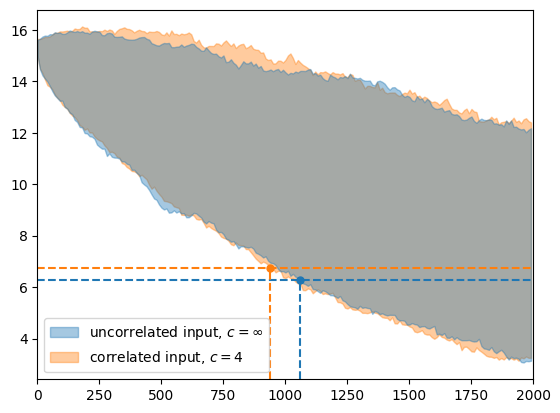

In [8]:
xmax = 2000
plot_point_spacing = 10
plt.fill_between(np.arange(0, xmax, plot_point_spacing), upper99_transient_coeff_infty[::plot_point_spacing], lower01_transient_coeff_infty[::plot_point_spacing], color='C0', alpha=0.4, label='uncorrelated input, $c=\infty$', zorder=2)

plt.fill_between(np.arange(0, xmax, plot_point_spacing), upper99_transient_coeff4[::plot_point_spacing], lower01_transient_coeff4[::plot_point_spacing], color='C1', alpha=0.4, label='correlated input, $c=4$', zorder=1)

y_min, y_max = plt.ylim()

plt.hlines(y=upper99_coeff_infty[0], xmin=0, xmax=xmax, colors='C0', linestyles='--', linewidth=1.5)
plt.vlines(x=capa_coeff_infty[0], ymin=y_min, ymax=upper99_coeff_infty[0], colors='C0', linestyles='--', linewidth=1.5)
plt.hlines(y=upper99_coeff4[0], xmin=0, xmax=xmax, colors='C1', linestyles='--', linewidth=1.5)
plt.vlines(x=capa_coeff4[0], ymin=y_min, ymax=upper99_coeff4[0], colors='C1', linestyles='--', linewidth=1.5)

plt.plot(capa_coeff_infty, upper99_coeff_infty, color='C0', marker='o', markersize=5)
plt.plot(capa_coeff4, upper99_coeff4, color='C1', marker='o', markersize=5)

plt.xlim(0, xmax)
plt.ylim(y_min, y_max)

plt.legend()

plt.savefig